# Projeto de IA — Modelagem de Ciclos de Atividade Solar
## Notebook 01 — Exploração e verificação dos dados

**Objetivo desta etapa:** conhecer a série anual de números de manchas solares antes de construir os modelos de previsão. Vamos carregar os dados, verificar sua estrutura, produzir estatísticas descritivas, visualizar a evolução temporal e fazer uma primeira investigação da periodicidade.

### Decisões metodológicas deste notebook
- A base principal será a série `sunspots` disponibilizada pelo **Statsmodels**, pois ela contém os valores e os anos correspondentes.
- O arquivo TXT fornecido pelo grupo será comparado com essa base, quando estiver acessível. A comparação não pressupõe que os dois arquivos sejam rigorosamente idênticos.
- A série é anual. Cada observação representa um ano; portanto, diferenças de um ano correspondem a um passo temporal.
- Esta etapa é exploratória. A inspeção visual ou um pico espectral, isoladamente, não prova que exista um ciclo perfeitamente regular.

> **Importante:** não embaralhe as observações. Em séries temporais, a ordem cronológica precisa ser preservada, inclusive nas futuras divisões entre treino e teste.

### Como executar
1. Instale as bibliotecas listadas na célula de dependências, caso ainda não estejam instaladas.
2. Abra este arquivo no Jupyter Notebook ou no VS Code com a extensão Jupyter.
3. Execute as células de cima para baixo (`Run All`).
4. Para comparar com o TXT, coloque-o em `data/sunspots.txt` ou ajuste a variável `CAMINHO_TXT` na célula de carregamento.

**Resultado esperado:** ao final, o grupo terá uma descrição inicial da base e figuras que poderão ser usadas para discutir o comportamento histórico da atividade solar.

## 1. Preparação do ambiente

As bibliotecas abaixo serão usadas nesta etapa. A instalação é feita no terminal, não dentro do código Python.

In [21]:
# Execute no terminal, se alguma biblioteca ainda não estiver instalada:
# python -m pip install pandas numpy matplotlib scipy statsmodels scikit-learn jupyter


In [22]:
# Importação das bibliotecas
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import periodogram, detrend
from statsmodels.datasets import sunspots
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Configurações visuais básicas
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

pd.set_option("display.precision", 3)

print("Bibliotecas carregadas com sucesso.")

Bibliotecas carregadas com sucesso.


## 2. Carregamento da série principal

O Statsmodels disponibiliza a base `sunspots` com duas colunas: `YEAR` (ano) e `SUNACTIVITY` (número anual de manchas solares). Vamos manter essas informações explicitamente no DataFrame.

In [23]:
# Carrega a base que acompanha o Statsmodels
base_original = sunspots.load_pandas().data.copy()

# Padroniza os nomes e os tipos das colunas
base = base_original.rename(
    columns={"YEAR": "ano", "SUNACTIVITY": "manchas_solares"}
).copy()

base["ano"] = base["ano"].astype(int)
base["manchas_solares"] = pd.to_numeric(
    base["manchas_solares"], errors="coerce"
)

# O índice temporal facilita gráficos e análises posteriores.
base = base.set_index("ano").sort_index()

print(f"Quantidade de observações: {len(base)}")
print(f"Primeiro ano: {base.index.min()}")
print(f"Último ano: {base.index.max()}")
display(base.head())
display(base.tail())

Quantidade de observações: 309
Primeiro ano: 1700
Último ano: 2008


,manchas_solares
ano,
1700,5.0
1701,11.0
1702,16.0
1703,23.0
1704,36.0


,manchas_solares
ano,
2004,40.4
2005,29.8
2006,15.2
2007,7.5
2008,2.9


## 3. Verificação da qualidade e da continuidade temporal

Antes de analisar uma série, precisamos verificar valores ausentes, duplicações, tipos incorretos e possíveis lacunas nos anos. Uma sequência anual contínua deve avançar de um em um ano.

In [24]:
# Informações gerais e tipos
print("Informações da base:")
base.info()

print("\nValores ausentes por coluna:")
display(base.isna().sum().to_frame("quantidade_ausente"))

print("Anos duplicados:", int(base.index.duplicated().sum()))

# Verifica se há intervalos maiores que um ano
anos = base.index.to_numpy()
diferencas_entre_anos = np.diff(anos)
anos_com_lacuna = anos[1:][diferencas_entre_anos > 1]

if len(anos_com_lacuna) == 0:
    print("A sequência de anos não apresenta lacunas.")
else:
    print("Possíveis lacunas antes dos anos:", anos_com_lacuna.tolist())

print("\nResumo numérico:")
display(base["manchas_solares"].describe().to_frame().T)

Informações da base:
<class 'pandas.DataFrame'>
RangeIndex: 309 entries, 1700 to 2008
Data columns (total 1 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   manchas_solares  309 non-null    float64
dtypes: float64(1)
memory usage: 2.5 KB

Valores ausentes por coluna:


,quantidade_ausente
manchas_solares,0


Anos duplicados: 0
A sequência de anos não apresenta lacunas.

Resumo numérico:


,count,mean,std,min,25%,50%,75%,max
manchas_solares,309.0,49.752,40.453,0.0,16.0,40.0,69.8,190.2


## 4. Comparação opcional com o TXT fornecido pelo grupo

O TXT disponibilizado contém 288 valores, enquanto a base do Statsmodels contém 309 observações anuais. A verificação abaixo procura o arquivo em alguns locais comuns. Se o arquivo não for encontrado, a célula apenas informa isso e o notebook continua normalmente.

**Cuidado com a interpretação:** comparar os valores pela ordem da lista é uma checagem inicial, não uma comprovação independente de proveniência ou de alinhamento dos anos. Para declarar o intervalo temporal do TXT com segurança, é necessário confirmar sua fonte/documentação.

In [25]:
# Ajuste este caminho, caso o TXT esteja em outro local.
CAMINHO_TXT = Path("data/sunspots.txt")

# Locais alternativos úteis quando o notebook é executado neste ambiente.
candidatos_txt = [
    CAMINHO_TXT,
    Path("Projeto_10_Series_Temporais_Sunspot.txt"),
    Path("/mnt/data/Projeto_10_Series_Temporais_Sunspot.txt"),
]

arquivo_txt = next((p for p in candidatos_txt if p.exists()), None)

if arquivo_txt is None:
    print("TXT não encontrado. A comparação foi ignorada.")
    print("Coloque o arquivo em data/sunspots.txt ou ajuste CAMINHO_TXT.")
else:
    # Lê um número por linha, ignorando linhas vazias.
    valores_txt = pd.read_csv(
        arquivo_txt, header=None, comment="#", sep=r"\s+", engine="python"
    ).iloc[:, 0]
    valores_txt = pd.to_numeric(valores_txt, errors="coerce").dropna().to_numpy()

    print(f"Arquivo localizado: {arquivo_txt}")
    print(f"Quantidade de valores numéricos no TXT: {len(valores_txt)}")

    valores_statsmodels = base["manchas_solares"].to_numpy()
    n_comparavel = min(len(valores_txt), len(valores_statsmodels))

    if n_comparavel == 0:
        print("Não há valores suficientes para comparar.")
    else:
        txt_comp = valores_txt[:n_comparavel]
        stats_comp = valores_statsmodels[:n_comparavel]
        diferencas = txt_comp - stats_comp
        iguais = np.isclose(txt_comp, stats_comp, atol=1e-10, rtol=0)

        print(f"Valores comparados na mesma ordem: {n_comparavel}")
        print(f"Posições numericamente iguais: {int(iguais.sum())}")
        print(f"Posições com diferença: {int((~iguais).sum())}")
        print(f"Diferença absoluta média: {np.mean(np.abs(diferencas)):.6f}")

        indices_diferentes = np.flatnonzero(~iguais)
        if len(indices_diferentes):
            print("Primeiras posições diferentes (índice começando em zero):")
            for i in indices_diferentes[:10]:
                print(
                    f"posição {i}: TXT={txt_comp[i]} | "
                    f"Statsmodels={stats_comp[i]} | "
                    f"diferença={diferencas[i]:.3f}"
                )
        else:
            print("Os valores comparados coincidem nessa sequência inicial.")

        if len(valores_txt) != len(valores_statsmodels):
            print(
                "Atenção: os arquivos têm quantidades diferentes de observações. "
                "Não complete nem descarte valores sem confirmar a fonte e o período."
            )

Arquivo localizado: Projeto_10_Series_Temporais_Sunspot.txt
Quantidade de valores numéricos no TXT: 288
Valores comparados na mesma ordem: 288
Posições numericamente iguais: 284
Posições com diferença: 4
Diferença absoluta média: 0.001736
Primeiras posições diferentes (índice começando em zero):
posição 262: TXT=37.5 | Statsmodels=37.6 | diferença=-0.100
posição 280: TXT=154.7 | Statsmodels=154.6 | diferença=0.100
posição 281: TXT=140.5 | Statsmodels=140.4 | diferença=0.100
posição 287: TXT=29.2 | Statsmodels=29.4 | diferença=-0.200
Atenção: os arquivos têm quantidades diferentes de observações. Não complete nem descarte valores sem confirmar a fonte e o período.


## 5. Visualização da série histórica

O primeiro gráfico permite observar a evolução anual da atividade solar. Os picos e vales sugerem oscilações, mas a regularidade e a duração dos ciclos devem ser avaliadas com ferramentas adicionais.

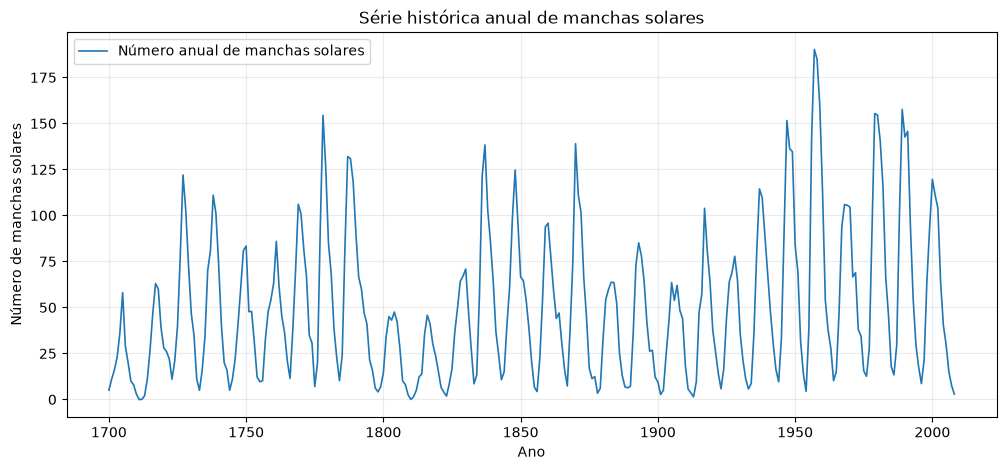

In [26]:
fig, ax = plt.subplots()
ax.plot(
    base.index,
    base["manchas_solares"],
    linewidth=1.2,
    label="Número anual de manchas solares",
)
ax.set_title("Série histórica anual de manchas solares")
ax.set_xlabel("Ano")
ax.set_ylabel("Número de manchas solares")
ax.legend()
plt.show()

## 6. Estatísticas descritivas e suavização visual

A tabela resume a distribuição dos valores. A média móvel de 11 anos é incluída apenas como recurso visual para suavizar oscilações de curto prazo. Ela **não** deve ser interpretada como prova de que todo ciclo dura exatamente 11 anos; além disso, suavizar a série remove parte das variações que também podem ser cientificamente importantes.

,valor
count,309.000
mean,49.752
median,40.000
std,40.453
min,0.000
max,190.200


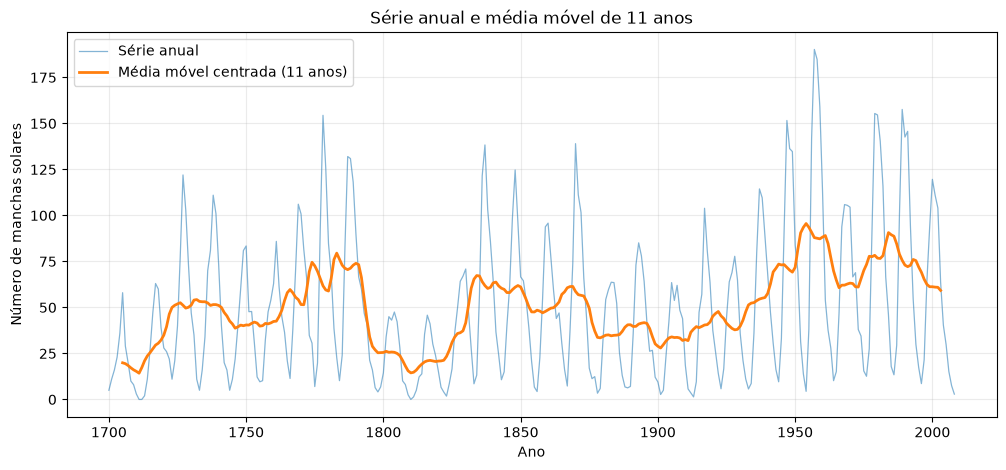

In [27]:
serie = base["manchas_solares"]

estatisticas = serie.agg(["count", "mean", "median", "std", "min", "max"])
display(estatisticas.to_frame(name="valor"))

# Média móvel centrada em uma janela de 11 observações anuais.
media_movel_11 = serie.rolling(window=11, center=True).mean()

fig, ax = plt.subplots()
ax.plot(serie.index, serie, alpha=0.55, linewidth=0.9, label="Série anual")
ax.plot(
    media_movel_11.index,
    media_movel_11,
    linewidth=2,
    label="Média móvel centrada (11 anos)",
)
ax.set_title("Série anual e média móvel de 11 anos")
ax.set_xlabel("Ano")
ax.set_ylabel("Número de manchas solares")
ax.legend()
plt.show()

## 7. Investigação inicial da periodicidade por análise espectral

O periodograma estima a distribuição da potência da série por frequência. Como os dados são anuais, uma frequência de 1/11 ciclo por ano corresponde a um período de aproximadamente 11 anos.

Para esta primeira inspeção, removemos uma tendência linear antes de calcular o periodograma. Isso é uma escolha exploratória; outras formas de pré-processamento podem alterar o espectro e deverão ser discutidas em etapas posteriores.

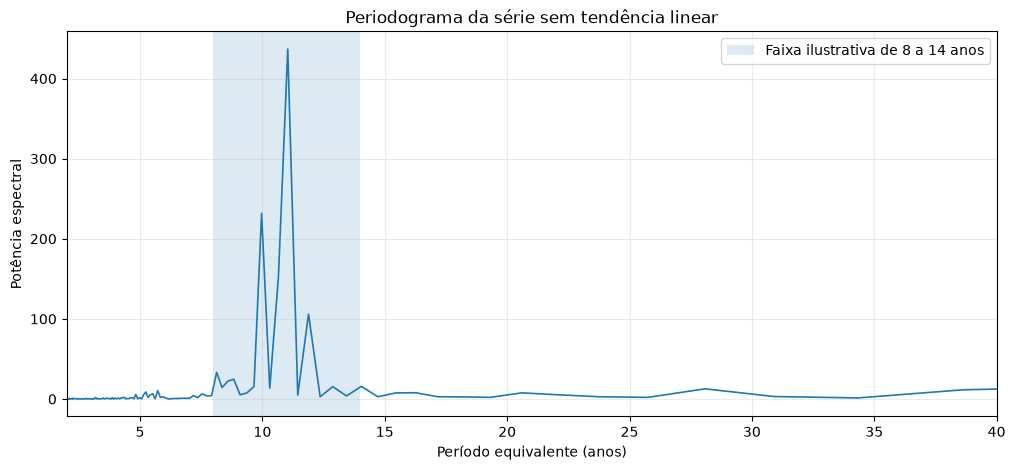

,periodo_anos,potencia
0,11.036,436.928
1,9.968,231.784
2,10.655,152.668
3,11.885,105.992
4,8.132,33.260


Maior pico entre 8 e 14 anos: 11.04 anos (potência 436.9).


In [28]:
# Frequência de amostragem = 1 observação por ano.
# A tendência linear é removida para reduzir seu efeito no espectro.
serie_sem_tendencia = detrend(serie.to_numpy(), type="linear")
frequencias, potencias = periodogram(
    serie_sem_tendencia,
    fs=1.0,
    detrend=False,
    scaling="spectrum",
)

# Frequência zero não representa um período finito; por isso é excluída.
mascara = frequencias > 0
frequencias_validas = frequencias[mascara]
potencias_validas = potencias[mascara]
periodos = 1 / frequencias_validas

fig, ax = plt.subplots()
ax.plot(periodos, potencias_validas, linewidth=1.2)
ax.axvspan(8, 14, alpha=0.15, label="Faixa ilustrativa de 8 a 14 anos")
ax.set_xlim(2, min(40, periodos.max()))
ax.set_title("Periodograma da série sem tendência linear")
ax.set_xlabel("Período equivalente (anos)")
ax.set_ylabel("Potência espectral")
ax.legend()
plt.show()

# Lista os cinco picos de maior potência entre períodos de 2 a 40 anos.
faixa_interesse = (periodos >= 2) & (periodos <= 40)
indices_faixa = np.flatnonzero(faixa_interesse)
indices_top = indices_faixa[
    np.argsort(potencias_validas[faixa_interesse])[-5:][::-1]
]

picos = pd.DataFrame({
    "periodo_anos": periodos[indices_top],
    "potencia": potencias_validas[indices_top],
}).sort_values("potencia", ascending=False)

display(picos.reset_index(drop=True))

# Identifica o maior pico dentro de uma faixa próxima ao ciclo de Schwabe.
faixa_schwabe = (periodos >= 8) & (periodos <= 14)
if faixa_schwabe.any():
    idx_local = np.flatnonzero(faixa_schwabe)[
        np.argmax(potencias_validas[faixa_schwabe])
    ]
    print(
        "Maior pico entre 8 e 14 anos: "
        f"{periodos[idx_local]:.2f} anos "
        f"(potência {potencias_validas[idx_local]:.4g})."
    )
else:
    print("Não há frequências avaliadas na faixa de 8 a 14 anos.")

### Como interpretar o periodograma

- Um pico em torno de 11 anos é compatível com a presença de uma componente próxima ao ciclo de Schwabe.
- Picos em outros períodos podem indicar variabilidade em escalas diferentes ou efeitos da duração limitada da série.
- O periodograma global resume toda a série e não mostra se a duração ou a intensidade do ciclo mudou ao longo dos séculos.
- A resolução espectral depende do comprimento da série. Não devemos apresentar o período estimado como um número exato ou constante.

## 8. Autocorrelação: primeira inspeção

A função de autocorrelação (ACF) mede a relação da série com versões deslocadas no tempo. Um padrão de oscilações na ACF pode ajudar a identificar dependências temporais e possíveis periodicidades. Nesta etapa, usamos até 30 defasagens (lags), ou seja, até 30 anos.

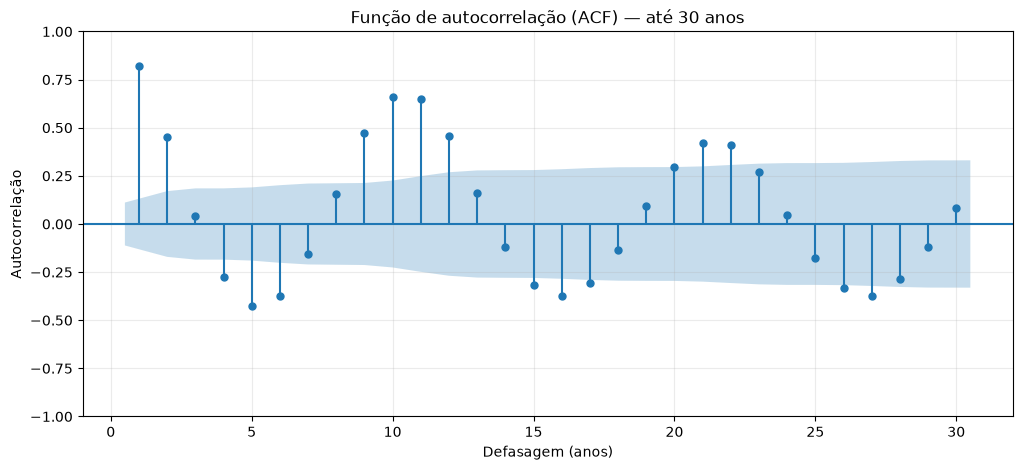

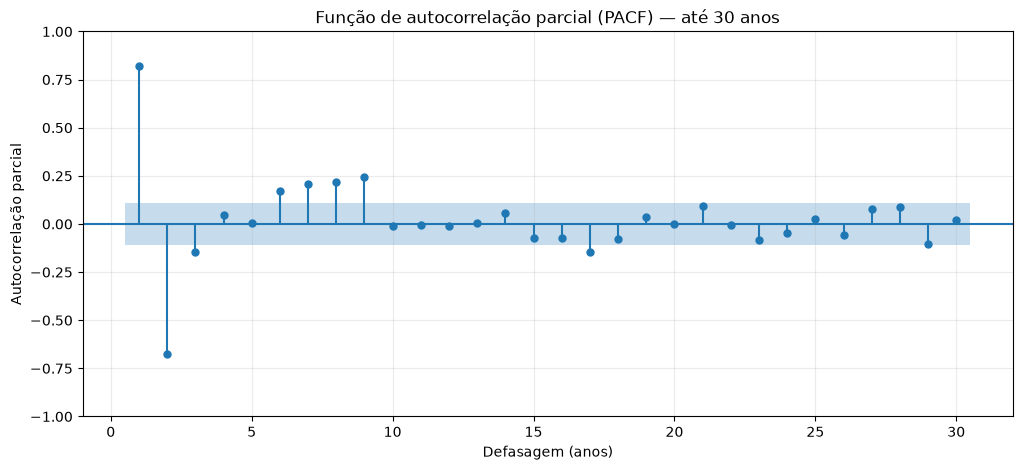

In [29]:
fig, ax = plt.subplots()
plot_acf(serie, lags=30, ax=ax, zero=False)
ax.set_title("Função de autocorrelação (ACF) — até 30 anos")
ax.set_xlabel("Defasagem (anos)")
ax.set_ylabel("Autocorrelação")
plt.show()

fig, ax = plt.subplots()
plot_pacf(serie, lags=30, method="ywm", ax=ax, zero=False)
ax.set_title("Função de autocorrelação parcial (PACF) — até 30 anos")
ax.set_xlabel("Defasagem (anos)")
ax.set_ylabel("Autocorrelação parcial")
plt.show()

## 9. Testes iniciais de estacionariedade (ADF e KPSS)

Os testes ADF e KPSS usam hipóteses nulas diferentes:
- **ADF:** hipótese nula de presença de raiz unitária (não estacionariedade, sob as condições do teste).
- **KPSS:** hipótese nula de estacionariedade em torno de nível ou tendência, conforme a especificação.

Os resultados devem ser interpretados em conjunto e com atenção às especificações. Nesta célula, testamos a série em nível com constante. Isso é um diagnóstico inicial, não uma decisão automática sobre diferenciação ou sobre o modelo ARIMA.

In [30]:
# ADF: H0 = a série possui raiz unitária.
resultado_adf = adfuller(serie.dropna(), regression="c", autolag="AIC")

# KPSS: H0 = estacionariedade em torno de um nível (regression="c").
with warnings.catch_warnings(record=True) as avisos_kpss:
    warnings.simplefilter("always")
    resultado_kpss = kpss(serie.dropna(), regression="c", nlags="auto")

resumo_testes = pd.DataFrame(
    {
        "teste": ["ADF", "KPSS"],
        "estatistica": [resultado_adf[0], resultado_kpss[0]],
        "p_valor": [resultado_adf[1], resultado_kpss[1]],
        "lags_utilizados": [resultado_adf[2], resultado_kpss[2]],
    }
)
display(resumo_testes)

print("\nHipóteses nulas:")
print("ADF: presença de raiz unitária.")
print("KPSS: estacionariedade em torno de um nível.")

if avisos_kpss:
    print("\nAviso(s) retornado(s) pelo KPSS:")
    for aviso in avisos_kpss:
        print("-", str(aviso.message))

/var/folders/vx/j5k4tg5s21753jltv498n43r0000gn/T/ipykernel_66176/1067767558.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado_adf = adfuller(serie.dropna(), regression="c", autolag="AIC")


,teste,estatistica,p_valor,lags_utilizados
0,ADF,-2.838,0.053,8
1,KPSS,0.670,0.016,7



Hipóteses nulas:
ADF: presença de raiz unitária.
KPSS: estacionariedade em torno de um nível.

Aviso(s) retornado(s) pelo KPSS:
- kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.


## 10. Registro das observações da equipe

Preencham esta seção depois de executar o notebook. Evitem apenas descrever o desenho dos gráficos: registrem o que observaram, qual evidência sustenta a afirmação e quais limitações permanecem.

### Perguntas para discussão

1. Qual é o intervalo de anos coberto pela base principal e quantas observações existem?
2. Há valores ausentes, anos duplicados ou lacunas na sequência anual?
3. O TXT do grupo coincide integralmente com a série do Statsmodels? Quais diferenças foram encontradas? O que ainda precisa ser confirmado sobre a origem e o período do TXT?
4. Visualmente, os picos parecem ocorrer em intervalos perfeitamente regulares? Que variações de intensidade ou duração são perceptíveis?
5. Qual período aparece como pico relevante no periodograma? Ele está próximo da faixa esperada para o ciclo de Schwabe?
6. O que ACF e PACF sugerem sobre as dependências temporais? Há limitações na interpretação desses gráficos em uma série oscilatória?
7. ADF e KPSS apontam na mesma direção? Como explicar a diferença entre as hipóteses nulas?

### Modelo para registrar uma conclusão preliminar

> A série analisada contém **[número]** observações anuais, de **[ano inicial]** a **[ano final]**. Na inspeção visual, observamos **[descrição baseada no gráfico]**. A análise espectral indicou um pico relevante em torno de **[período calculado]** anos. Os testes ADF e KPSS **[resumir resultados sem confundir as hipóteses]**. Esses resultados são preliminares e serão aprofundados nas etapas de modelagem e avaliação fora da amostra.

## 11. Próxima etapa do projeto

Depois de discutir os resultados deste notebook, a equipe poderá avançar para a análise estatística mais detalhada e a modelagem. O roteiro previsto é:

1. aprofundar a análise de estacionariedade, ACF e PACF;
2. definir uma divisão cronológica entre treino e teste;
3. ajustar e diagnosticar um modelo ARIMA;
4. construir um modelo de aprendizado de máquina com defasagens temporais (por exemplo, Random Forest);
5. comparar os modelos nos mesmos anos de teste, usando MAE, RMSE, MAPE e R², com ressalvas para o MAPE quando houver valores reais iguais ou próximos de zero.

**Não escolha ainda os melhores parâmetros do ARIMA nem ajuste o modelo de ML neste notebook.** A função desta primeira etapa é entender e validar os dados.